In [1]:
from pyspecter import SPECTER

from pyspecter.SPECTER import SPECTER

import numpy as np
import matplotlib.pyplot as plt
import time
import itertools
from tqdm import tqdm

%matplotlib inline

In [2]:
def sw2_non_square(events1, events2, n_samples, batch_size, specter: SPECTER):
    # Generate all (i,j) index pairs
    # i_flat = [0,0,0,…,1,1,1,…,n-1,n-1,n-1]
    # j_flat = [0,1,2,…,0,1,2,…,0,1,2]
    i_idx, j_idx = np.meshgrid(np.arange(n_samples),
                            np.arange(n_samples),
                            indexing='ij')
    i_flat = i_idx.ravel()
    j_flat = j_idx.ravel()

    # Prepare output matrix
    pairwise_emds = np.zeros((n_samples, n_samples))

    total_pairs = len(i_flat)
    for start in tqdm(range(0, total_pairs, batch_size)):
        end = start + batch_size
        ib = i_flat[start:end]
        jb = j_flat[start:end]

        # batch of event pairs
        emd_vals = specter.spectralEMD(events1[ib], events2[jb])

        # scatter them back into the full matrix
        pairwise_emds[ib, jb] = emd_vals
        
    return pairwise_emds

def sw2_square(events, n_samples, batch_size, specter: SPECTER): 
    # Get list of pairwise indices
    i_pairs, j_pairs = np.triu_indices(n_samples, k = 1)

    # Initialize matrix to store pairwise EMDs
    pairwise_emds = np.zeros((n_samples, n_samples))

    # Compute batches
    start_time = time.time()
    for n in tqdm(range(0, len(i_pairs), batch_size)):
        
        i_batch = i_pairs[n : n + batch_size]
        j_batch = j_pairs[n : n + batch_size]
        
        # Compute the pairwise EMDs
        emds = specter.spectralEMD(events[i_batch], events[j_batch])
        
        # Store the results
        pairwise_emds[i_batch, j_batch] = emds
        pairwise_emds[j_batch, i_batch] = emds
    
    return pairwise_emds

In [3]:
n_samples = 1000
batch_size = 250 # Number of pairs to process in parallel, can probably be increased.

In [4]:
dataset_length = 1000
num_dataset = 8
num_particles = 150
num_attr = 4

data_path = '../mini_dataset/'
file_names = ['QCD_1k.npz' ,'HToBB_1k.npz' ,'HToCC_1k.npz','HToGG_1k.npz','HToWW4Q_1k.npz','ZToQQ_1k.npz','WToQQ_1k.npz','TTBar_1k.npz']

all_events = np.zeros((num_dataset * dataset_length, num_particles, num_attr))
all_labels = np.zeros(num_dataset * dataset_length)

event_blocks = np.zeros((num_dataset, dataset_length, num_particles, num_attr))

for i, file in enumerate(file_names):
    f = np.load(data_path + file)
    
    x = f['x']
    y = f['y']
    
    all_events[i*1000:(i+1)*1000] = x
    all_labels[i*1000:(i+1)*1000] = y

In [5]:
specter = SPECTER(compile=True)

Compiling SPECTER model...
Generating test events for tracing ...
Test events generated! Time taken:  0.7389700412750244  seconds.
Compiling spectral representation functions ...
Compiling observables...
Observables compiled! Time taken:  3.8459880352020264  seconds.
Compilation complete! Time taken:  3.845999002456665  seconds.


In [6]:
events = all_events[:1000, :, :3]

In [7]:
pairwise_emds = sw2_square(events, n_samples, batch_size, specter)

100%|██████████| 1998/1998 [14:38<00:00,  2.28it/s]


In [8]:
# block = np.zeros((dataset_length, dataset_length))
# for i,j in itertools.combinations_with_replacement(range(num_dataset), 2):
#     if i == j:
#         block = sw2_square(all_events[i*1000:(i+1)*1000], n_samples, batch_size, specter)
#     else:
#         block = sw2_non_square(all_events[i*1000:(i+1)*1000], all_events[j*1000:(j+1)*1000], n_samples, batch_size, specter)
        
#     np.save(f'block_{i}_{j}_sw2', block)

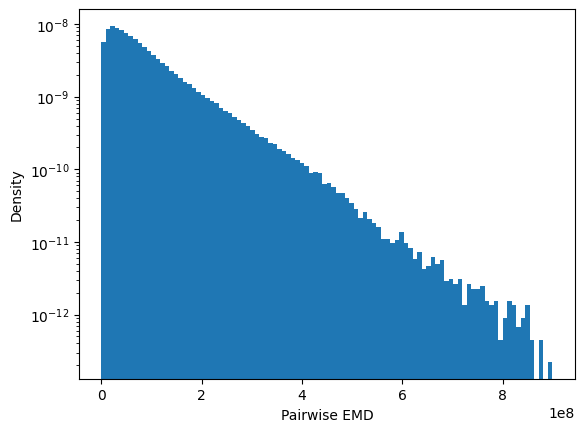

In [9]:
plt.hist(pairwise_emds[np.triu_indices(n_samples, k = 1)], bins = 100, density=True)
plt.yscale('log')
plt.xlabel("Pairwise EMD")
plt.ylabel("Density")
plt.show()

In [10]:
pairwise_emds[:5, :5]

array([[       0., 10471918., 33682520., 31141022., 18178864.],
       [10471918.,        0., 18935828., 15485235., 21047640.],
       [33682520., 18935828.,        0.,  1489481., 47485708.],
       [31141022., 15485235.,  1489481.,        0., 38753328.],
       [18178864., 21047640., 47485708., 38753328.,        0.]])